In [1]:
import re
import csv
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)

RAW_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/data/raw")                              # input  – never modified
OUT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/intermediate/stage2_cleaned")      # cleaned trips (one CSV per trip)
REPORT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/outputs/stage2_cleaning")            # logs, tables and figures
OUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
CFG = {
    # --- physical limits (BYD Atto 3, 126-cell LFP pack, 150 kW motor)
    "speed_max_kmh": 200,          # Atto 3 top speed is 160 km/h; 255 is the 0xFF "no answer" code
    "rpm_max": 13000,              # 160 km/h x ~78 rpm per km/h = ~12,500 rpm
    "voltage_range_v": (315, 460), # 126 cells x 2.5 V (empty) ... 126 x 3.65 V (full)
    "current_abs_max_a": 500,      # 150 kW / 315 V = ~476 A at the lowest pack voltage
    "soc_range_pct": (0, 100),
    "sri_lanka_lat": (5.9, 9.9),
    "sri_lanka_lon": (79.5, 82.0),
    # --- driving-behaviour limits (used only to find sensor spikes)
    "spike_accel_ms2": 5.0,        # Atto 3 0-100 km/h in ~7.3 s = 3.8 m/s2 average
    # --- GPS
    "gps_jump_m": 25,              # phone GPS noise is ~3-5 m; 25 m is 5x larger
    "gps_jump_window": 11,         # fixes used for the local median track (~11 s)
    "gps_jump_max_window_s": 15,   # only judge jumps where those fixes are close in time
    # --- gaps and trimming
    "moving_kmh": 5,               # above this the vehicle is moving
    "logging_gap_s": 60,           # no rows at all -> new segment (no interpolation across it)
    "obd_gap_s": 12,               # > 3 polling cycles (3 x 3.7 s) without OBD data
    "gps_gap_s": 30,               # no new GPS fix for 30 s while moving
    "trim_margin_s": 15,           # keep 15 s (= 4 speed readings) before first / after last movement
}
pd.Series(CFG, name="value").to_frame()

,value
speed_max_kmh,200
rpm_max,13000
voltage_range_v,"(315, 460)"
current_abs_max_a,500
soc_range_pct,"(0, 100)"
sri_lanka_lat,"(5.9, 9.9)"
sri_lanka_lon,"(79.5, 82.0)"
spike_accel_ms2,5.0
gps_jump_m,25
gps_jump_window,11


In [3]:
def find_raw_files(raw_dir):
    """All Car Scanner CSV exports under raw_dir, with the trip date/time from the file name."""
    rows = []
    if not raw_dir.exists():
        print(f"Warning: {raw_dir} directory does not exist.")
        return pd.DataFrame(columns=["trip_id", "file", "path", "file_datetime"])

    for f in sorted(raw_dir.rglob("*.csv")):
        m = re.search(r"(\d{4}-\d{2}-\d{2})[ _](\d{2}-\d{2}-\d{2})", f.name)
        if m:
            rows.append({"file": f.name, "path": f,
                         "file_datetime": pd.to_datetime(m.group(1) + " " + m.group(2), format="%Y-%m-%d %H-%M-%S")})

    if not rows:
        print(f"Warning: No matching CSV files found in {raw_dir}.")
        return pd.DataFrame(columns=["trip_id", "file", "path", "file_datetime"])

    files = pd.DataFrame(rows).sort_values("file_datetime").reset_index(drop=True)
    files.insert(0, "trip_id", [f"T{i:03d}" for i in range(1, len(files) + 1)])
    return files


def load_carscanner(path):
    """Read one Car Scanner CSV (same loader as Stage 1)."""
    path = Path(path)
    with open(path, encoding="utf-8") as f:
        header = next(csv.reader(f))
    names, seen = [], {}
    for h in header:
        h = h.strip() or "_empty"
        seen[h] = seen.get(h, 0) + 1
        names.append(h if seen[h] == 1 else f"{h} #{seen[h]}")
    df = pd.read_csv(path, header=None, skiprows=1, names=names, dtype=str)
    df = df.drop(columns=["_empty"], errors="ignore")
    value_cols = [c for c in df.columns if c != "time"]
    df[value_cols] = df[value_cols].apply(pd.to_numeric, errors="coerce")
    date = re.search(r"\d{4}-\d{2}-\d{2}", path.name).group(0)
    ts = pd.to_datetime(date + " " + df["time"], format="%Y-%m-%d %H:%M:%S.%f")
    ts = ts + pd.to_timedelta((ts.diff().dt.total_seconds() < -43200).cumsum(), unit="D")
    df.insert(0, "timestamp", ts)
    df.insert(1, "t_s", (ts - ts.iloc[0]).dt.total_seconds())
    return df


def md5(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()


files = find_raw_files(RAW_DIR)
if not files.empty:
    raw_hash_before = {r["file"]: md5(r["path"]) for _, r in files.iterrows()}
    print(f"{len(files)} raw files found; fingerprints (MD5) recorded to prove they are not modified.")
else:
    raw_hash_before = {}
    print("No raw files found. Please ensure your files are uploaded to the correct directory.")

77 raw files found; fingerprints (MD5) recorded to prove they are not modified.


In [4]:
def column_evidence(files):
    """Facts about every raw column, measured over all files."""
    stats = {}
    checks = {"speed_duplicate_equal": [], "rpm_mirror_equal": [], "torque_mirror_equal": [], "power_equals_VI": []}
    for _, row in files.iterrows():
        df = load_carscanner(row["path"])
        startup_end = df["t_s"].iloc[0] + 60
        for c in df.columns:
            if c in ("timestamp", "t_s"):
                continue
            v = df[c].dropna()
            s = stats.setdefault(c, {"readings": 0, "values": set(), "after_startup": 0, "files_with_data": 0})
            s["readings"] += len(v)
            s["files_with_data"] += int(len(v) > 0)
            s["after_startup"] += int((df.loc[v.index, "t_s"] > startup_end).sum()) if c != "time" else len(v)
            if c != "time" and len(s["values"]) < 50:
                s["values"].update(v.round(6).unique()[:50])
        # relationships between columns (only rows where both are present)
        a, b = df["[PDC] Vehicle speed (km/h)"], df["[PDC] Vehicle speed (km/h) #2"]
        m = a.notna() & b.notna()
        checks["speed_duplicate_equal"].append(bool((a[m] == b[m]).all()))
        a, b = df["[MMCU] Main Drive motor RPM (rpm)"], df["Motor speed v.2 (rpm)"]
        m = a.notna() & b.notna()
        checks["rpm_mirror_equal"].append(bool((a[m] == -b[m]).all()))
        a, b = df["[MMCU] Main Drive motor Torque (N⋅m)"], df["Motor torque v.2 (N⋅m)"]
        m = a.notna() & b.notna()
        checks["torque_mirror_equal"].append(bool((a[m].round(1) == -b[m].round(1)).all()))
        ff = df.ffill()
        m = df["HV EV Battery Power (kW)"].notna()
        diff = (df.loc[m, "HV EV Battery Power (kW)"]
                - ff.loc[m, "[BASU] Battery total voltage (V)"] * ff.loc[m, "[BASU] Battery total current (A)"] / 1000)
        checks["power_equals_VI"].append(bool(diff.abs().max() < 1e-6))
    ev = pd.DataFrame({
        c: {"readings_total": s["readings"],
            "readings_per_file": round(s["readings"] / len(files), 1),
            "distinct_values": ("50+" if len(s["values"]) >= 50 else len(s["values"])) if c != "time" else "-",
            "after_first_60s_%": round(100 * s["after_startup"] / s["readings"], 1) if s["readings"] else 0}
        for c, s in stats.items()}).T
    return ev, {k: f"{sum(v)}/{len(v)} files" for k, v in checks.items()}


evidence, relation_checks = column_evidence(files)
print("Relationships verified across all files:")
for k, v in relation_checks.items():
    print(f"  {k:24s}: true in {v}")
evidence

Relationships verified across all files:
  speed_duplicate_equal   : true in 77/77 files
  rpm_mirror_equal        : true in 77/77 files
  torque_mirror_equal     : true in 77/77 files
  power_equals_VI         : true in 77/77 files


,readings_total,readings_per_file,distinct_values,after_first_60s_%
time,642588,8345.3,-,100.0
[BASU] Battery total current (A),44500,577.9,50+,97.8
[BASU] Battery total voltage (V),44508.0,578.0,33.0,97.8
[BASU] Highest temperature cell value (℃),44141.0,573.3,10.0,98.6
[BASU] Highest voltage cell value (V),44280,575.1,50+,98.3
[BASU] HV Battery Pack Current Nominal Capacity (Ah),44335.0,575.8,1.0,98.2
[BASU] HV Battery Pack Current Nominal SoC (%),44335,575.8,50+,98.2
[BASU] HV Battery Pack Factory Capacity (Ah),44197.0,574.0,1.0,98.5
[BASU] HV Battery Pack Factory SoC (%),44197.0,574.0,3.0,98.5
[BASU] Lowest temperature cell value (℃),44148.0,573.4,12.0,98.6


In [5]:
K_CORE = "KEEP – core driving signal"
K_POS = "KEEP – vehicle position"
K_EV = "KEEP – input for EV energy features (Stage 7)"
K_CHECK = "KEEP – independent cross-check"
D_DUP = "DROP – exact duplicate of another column (verified)"
D_MIRROR = "DROP – sign-inverted copy of another column (verified)"
D_CONST = "DROP – constant within each trip, no time information (value kept in trip_metadata.csv)"
D_STARTUP = "DROP – read only during connection start-up, not a time series"
D_DERIVED = "DROP – calculated by the app from other columns; recalculated from cleaned data later"
D_CUMUL = "DROP – app counter that runs across trips (depends on app history, not this trip)"
D_SCOPE = "DROP – outside the scope of driving-cycle construction (kept in raw data)"

COLUMN_PLAN = {
    "time": ("DROP – replaced by full 'timestamp' (date from file name + this clock time)", None),
    "[PDC] Vehicle speed (km/h)": (K_CORE + ": vehicle speed from the car, basis of the driving cycle", "speed_kmh"),
    "[PDC] Vehicle speed (km/h) #2": (D_DUP, None),
    "[MMCU] Main Drive motor RPM (rpm)": (K_CHECK + ": fixed gear ratio, so RPM confirms vehicle speed", "motor_rpm"),
    "Motor speed v.2 (rpm)": (D_MIRROR, None),
    "[BASU] Battery total current (A)": (K_EV + ": battery power = voltage x current", "battery_current_a"),
    "[BASU] Battery total voltage (V)": (K_EV + ": battery power = voltage x current", "battery_voltage_v"),
    "[BASU] HV Battery Pack Current Nominal SoC (%)": (K_EV + ": state-of-charge change per segment", "soc_pct"),
    "Latitude": (K_POS + ": needed for map matching and environment labelling", "gps_lat"),
    "Longtitude": (K_POS + ": needed for map matching and environment labelling", "gps_lon"),
    "Speed (GPS) (km/h)": (K_CHECK + ": second speed source at ~1 Hz, used in Stage 3 synchronisation", "gps_speed_kmh"),
    "Altitude (GPS) (m)": ("KEEP – optional context: road gradient (phone altitude is low accuracy)", "gps_altitude_m"),
    "HV EV Battery Power (kW)": (D_DERIVED + " (verified = V x I / 1000)", None),
    "Energy used (kWh)": (D_DERIVED + " (running sum of power; would carry invalid readings)", None),
    "Energy costs ($)": (D_DERIVED + " (= energy used x tariff setting)", None),
    "EV Instant Energy Consumption (distance/kWh) (km/kWh)": (D_DERIVED + " (ratio; undefined when stationary)", None),
    "EV Instant Energy Consumption (kWh) (kWh)": (D_DERIVED, None),
    "EV Instant Energy Consumption (kWh/distance) (kWh/100km)": (D_DERIVED + " (ratio; undefined when stationary)", None),
    "Average speed (km/h)": (D_DERIVED + " (running average of OBD speed)", None),
    "Average speed (GPS) (km/h)": (D_DERIVED + " (running average of GPS speed)", None),
    "Distance travelled (km)": (D_DERIVED + " (integral of OBD speed)", None),
    "Distance travelled (Today) (km)": (D_CUMUL, None),
    "Distance travelled (Week) (km)": (D_CUMUL, None),
    "Distance travelled (total) (km)": (D_CUMUL, None),
    "Vehicle acceleration (g)": (D_DERIVED + " (rarely logged; acceleration is computed from cleaned speed in Stage 7)", None),
    "Cell voltage delta (mV)": (D_DERIVED + " (highest - lowest cell, read at different times -> artefacts)", None),
    "Cell voltage delta (mV) #2": (D_DUP, None),
    "Battery SOH (calculated) (%)": (D_CONST, None),
    "Battery SOH (calculated) (%) #2": (D_DUP, None),
    "[BASU] HV Battery Pack Current Nominal Capacity (Ah)": (D_CONST, None),
    "[BASU] HV Battery Pack Factory Capacity (Ah)": (D_CONST, None),
    "[BASU] HV Battery Pack Factory SoC (%)": (D_CONST + "; meaning not documented", None),
    "[PDC] Vehicle operation mode ()": (D_CONST, None),
    "[BASU] Times off full power [second-rate] ()": (D_STARTUP, None),
    "[MMCU] Main Drive motor Power (kW)": (D_STARTUP, None),
    "[MMCU] Main Drive motor Torque (N⋅m)": (D_STARTUP, None),
    "Motor torque v.2 (N⋅m)": (D_MIRROR, None),
    "[MMCU] Main Drive motor Temperature (℃)": (D_STARTUP, None),
    "[BASU] Pack 1 highest temperature cell value (℃)": (D_STARTUP, None),
    "[BASU] Pack 1 lowest temperature cell number ()": (D_STARTUP, None),
    "[BASU] Pack 1 lowest temperature cell value (℃)": (D_STARTUP, None),
    "[BASU] Pack 1 Lowest voltage cell value (V)": (D_STARTUP, None),
    "[BASU] Pack 6 lowest temperature cell number ()": (D_STARTUP, None),
    "[BASU] Pack 6 lowest temperature cell value (℃)": (D_STARTUP, None),
    "[BASU] Pack 6 Lowest voltage cell value (V)": (D_STARTUP, None),
    "[BASU] Highest voltage cell value (V)": (D_SCOPE + ": individual cell voltages (battery health)", None),
    "[BASU] Lowest voltage cell value (V)": (D_SCOPE + ": individual cell voltages (battery health)", None),
    "[BASU] Highest temperature cell value (℃)": (D_SCOPE + ": battery thermal state", None),
    "[BASU] Lowest temperature cell value (℃)": (D_SCOPE + ": battery thermal state", None),
    "[BASU] Maximum allowed charge power (kW)": (D_SCOPE + ": battery management limits", None),
    "[BASU] Maximum allowed discharge power (kW)": (D_SCOPE + ": battery management limits", None),
    "[PDC] Water temperature (℃)": (D_SCOPE + ": coolant temperature", None),
}
# constant columns are stored once per trip in trip_metadata.csv instead of on every row
CONSTANT_META = {
    "Battery SOH (calculated) (%)": "battery_soh_pct",
    "[BASU] HV Battery Pack Current Nominal Capacity (Ah)": "nominal_capacity_ah",
    "[BASU] HV Battery Pack Factory Capacity (Ah)": "factory_capacity_ah",
    "[BASU] HV Battery Pack Factory SoC (%)": "factory_soc_pct",
    "[PDC] Vehicle operation mode ()": "operation_mode",
}

# Safety check: every raw column must have a documented decision – nothing is dropped silently
missing = sorted(set(evidence.index) - set(COLUMN_PLAN))
assert not missing, f"Columns without a decision: {missing}"

decisions = evidence.join(pd.DataFrame(
    {c: {"decision": r.split(" – ")[0], "reason": r.split(" – ", 1)[1], "new_name": n}
     for c, (r, n) in COLUMN_PLAN.items()}).T)
decisions = decisions[["decision", "new_name", "reason", "readings_per_file", "distinct_values", "after_first_60s_%"]]
decisions.index.name = "raw column"
decisions.sort_values(["decision", "reason"], ascending=[False, True]).to_csv(REPORT_DIR / "column_decisions.csv")
print(f"KEEP: {(decisions['decision'] == 'KEEP').sum()} columns   DROP: {(decisions['decision'] == 'DROP').sum()} columns")
decisions.sort_values(["decision", "reason"], ascending=[False, True])

KEEP: 9 columns   DROP: 43 columns


,decision,new_name,reason,readings_per_file,distinct_values,after_first_60s_%
raw column,,,,,,
[PDC] Vehicle speed (km/h),KEEP,speed_kmh,"core driving signal: vehicle speed from the car, basis of the driving cycle",574.7,50+,98.4
[MMCU] Main Drive motor RPM (rpm),KEEP,motor_rpm,"independent cross-check: fixed gear ratio, so RPM confirms vehicle speed",578.1,50+,97.8
Speed (GPS) (km/h),KEEP,gps_speed_kmh,"independent cross-check: second speed source at ~1 Hz, used in Stage 3 synchronisation",269.2,50+,98.1
[BASU] Battery total current (A),KEEP,battery_current_a,input for EV energy features (Stage 7): battery power = voltage x current,577.9,50+,97.8
[BASU] Battery total voltage (V),KEEP,battery_voltage_v,input for EV energy features (Stage 7): battery power = voltage x current,578.0,33.0,97.8
[BASU] HV Battery Pack Current Nominal SoC (%),KEEP,soc_pct,input for EV energy features (Stage 7): state-of-charge change per segment,575.8,50+,98.2
Altitude (GPS) (m),KEEP,gps_altitude_m,optional context: road gradient (phone altitude is low accuracy),269.2,50+,98.1
Latitude,KEEP,gps_lat,vehicle position: needed for map matching and environment labelling,8342.9,50+,98.0
Longtitude,KEEP,gps_lon,vehicle position: needed for map matching and environment labelling,8342.9,50+,98.0


In [6]:
def haversine_m(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371000 * np.arcsin(np.sqrt(a))


def count_stops(t, v, t_from, t_to):
    """Number of times the vehicle comes to rest (speed < 1 km/h after moving) between t_from and t_to."""
    m = (t >= t_from) & (t <= t_to)
    moving = (v[m] >= CFG["moving_kmh"]).astype(int)
    return int(((moving.shift(fill_value=0) == 1) & (v[m] < 1)).sum())


def clean_trip(raw, trip_id):
    """Apply the cleaning steps to one raw trip. Returns cleaned data, log, gaps and metadata."""
    log, gaps = [], []

    def note(step, column, n, rule, reason):
        log.append({"trip_id": trip_id, "step": step, "column": column, "n_affected": int(n),
                    "rule": rule, "reason": reason})

    meta = {"trip_id": trip_id, "raw_rows": len(raw),
            "raw_start": raw["timestamp"].iloc[0], "raw_end": raw["timestamp"].iloc[-1]}
    for c, name in CONSTANT_META.items():                    # constants -> metadata, not columns
        v = raw[c].dropna()
        meta[name] = v.mode().iloc[0] if len(v) else np.nan

    # ---- Step 1: exact duplicate rows -------------------------------------------------
    dup = raw.drop(columns=["t_s"]).duplicated()
    note("1 duplicate rows", "all", dup.sum(), "row identical to an earlier row (same time and values)",
         "a logger cannot take two measurements with the same timestamp; the copy adds no information")
    df = raw.loc[~dup].copy()

    # ---- Step 2: keep only the documented columns and rename them ---------------------
    keep = {c: n for c, (r, n) in COLUMN_PLAN.items() if n}
    df = df[["timestamp", "t_s"] + list(keep)].rename(columns=keep)   # decisions: column_decisions.csv

    # ---- Step 3: invalid decoded values -> missing ------------------------------------
    rules = {
        "speed_kmh": (df["speed_kmh"] < 0) | (df["speed_kmh"] > CFG["speed_max_kmh"]),
        "motor_rpm": df["motor_rpm"].abs() > CFG["rpm_max"],
        "battery_voltage_v": ~df["battery_voltage_v"].between(*CFG["voltage_range_v"]) & df["battery_voltage_v"].notna(),
        "battery_current_a": df["battery_current_a"].abs() > CFG["current_abs_max_a"],
        "soc_pct": ~df["soc_pct"].between(*CFG["soc_range_pct"]) & df["soc_pct"].notna(),
    }
    for col, bad in rules.items():
        note("3 invalid values", col, bad.sum(), "outside physical limits in CFG",
             "value is physically impossible for the BYD Atto 3, so it is a decoding/communication error")
        df.loc[bad, col] = np.nan

    # ---- Step 4: GPS – keep only genuine new fixes -----------------------------------
    pos = df[["gps_lat", "gps_lon"]]
    repeated = pos.notna().all(axis=1) & (pos.diff().fillna(1) == 0).all(axis=1)
    note("4 GPS repeated position", "gps_lat/gps_lon", repeated.sum(),
         "same coordinates as the previous row",
         "Car Scanner copies the last GPS fix into every row; a repeated value is not a new measurement")
    df.loc[repeated, ["gps_lat", "gps_lon"]] = np.nan

    outside = df["gps_lat"].notna() & (~df["gps_lat"].between(*CFG["sri_lanka_lat"])
                                       | ~df["gps_lon"].between(*CFG["sri_lanka_lon"]))
    note("4 GPS outside Sri Lanka", "gps_lat/gps_lon", outside.sum(), "outside Sri Lanka bounding box",
         "position cannot be outside the study area; typically a (0,0) or startup fix")
    df.loc[outside, ["gps_lat", "gps_lon"]] = np.nan

    # ---- Step 5: GPS jumps ------------------------------------------------------------
    fx = df.loc[df["gps_lat"].notna(), ["t_s", "gps_lat", "gps_lon"]]
    w, h = CFG["gps_jump_window"], CFG["gps_jump_window"] // 2
    med_lat = fx["gps_lat"].rolling(w, center=True, min_periods=5).median()
    med_lon = fx["gps_lon"].rolling(w, center=True, min_periods=5).median()
    dev = haversine_m(med_lat, med_lon, fx["gps_lat"], fx["gps_lon"])
    close_in_time = (fx["t_s"].shift(-h) - fx["t_s"].shift(h)) <= CFG["gps_jump_max_window_s"]
    jump_idx = fx.index[(dev > CFG["gps_jump_m"]) & close_in_time]
    note("5 GPS jumps", "gps_lat/gps_lon", len(jump_idx),
         f"fix > {CFG['gps_jump_m']} m from the median track of its neighbours",
         "a car cannot leave the road and return within seconds; phone multipath error")
    df.loc[jump_idx, ["gps_lat", "gps_lon"]] = np.nan

    # ---- Step 6: speed spikes (impossible acceleration up AND down) -------------------
    sp = df.loc[df["speed_kmh"].notna(), ["t_s", "speed_kmh"]]
    a_in = sp["speed_kmh"].diff() / 3.6 / sp["t_s"].diff()
    a_out = -sp["speed_kmh"].diff(-1) / 3.6 / (-sp["t_s"].diff(-1))
    lim = CFG["spike_accel_ms2"]
    spike = ((a_in > lim) & (a_out < -lim)) | ((a_in < -lim) & (a_out > lim))
    note("6 speed spikes", "speed_kmh", spike.sum(),
         f"jump in and out of a single reading faster than {lim} m/s2",
         "a single reading that rises and falls faster than the car can accelerate is a sensor spike; "
         "one-way changes (hard braking, strong acceleration) are real events and are NOT removed")
    df.loc[spike[spike].index, "speed_kmh"] = np.nan

    # ---- Step 7: trim idle time before departure and after arrival --------------------
    sp = df.loc[df["speed_kmh"].notna(), ["t_s", "speed_kmh"]]
    moving_t = sp.loc[sp["speed_kmh"] >= CFG["moving_kmh"], "t_s"]
    t0, t1 = df["t_s"].iloc[0], df["t_s"].iloc[-1]
    if len(moving_t):
        keep_from = max(t0, moving_t.iloc[0] - CFG["trim_margin_s"])
        keep_to = min(t1, moving_t.iloc[-1] + CFG["trim_margin_s"])
    else:
        keep_from, keep_to = t0, t0                          # vehicle never moved
    stops_raw = count_stops(sp["t_s"], sp["speed_kmh"], keep_from, keep_to)
    before = len(df)
    df = df[(df["t_s"] >= keep_from) & (df["t_s"] <= keep_to)].copy()
    note("7 trim idle ends", "rows", before - len(df),
         f"before first / after last movement (+/- {CFG['trim_margin_s']} s margin)",
         "parked time with the app open is not driving and would inflate the stop share; "
         "stops during the trip are kept")
    # incomplete trips are KEPT (the driving is valid) but flagged for Stage 6 segmentation
    meta["starts_while_moving"] = bool(len(sp) and sp["speed_kmh"].iloc[0] >= CFG["moving_kmh"])
    meta["ends_while_moving"] = bool(len(sp) and sp["speed_kmh"].iloc[-1] >= CFG["moving_kmh"])

    # ---- Step 8: drop rows that are now empty -----------------------------------------
    value_cols = [c for c in df.columns if c not in ("timestamp", "t_s")]
    empty = df[value_cols].isna().all(axis=1)
    note("8 empty rows", "rows", empty.sum(), "no value left in the row",
         "the row only held dropped columns or removed values; nothing is left to carry forward")
    df = df.loc[~empty].copy()

    # ---- Step 9: gaps and segments (recorded, NOT filled) ------------------------------
    t = df["t_s"]
    seg_break = t.diff() > CFG["logging_gap_s"]
    df["segment_id"] = seg_break.cumsum().astype(int)
    for i in df.index[seg_break]:
        prev_t = t.loc[:i].iloc[-2]
        gaps.append({"trip_id": trip_id, "type": "logging gap", "start_s": prev_t, "end_s": t[i]})

    obd = df[["speed_kmh", "motor_rpm", "battery_current_a", "battery_voltage_v", "soc_pct"]].notna().any(axis=1)
    ot = t[obd]
    for a, b in zip(ot.values[:-1], ot.values[1:]):
        other_rows_continue = ((t > a) & (t < b)).sum() >= (b - a) / 2      # GPS kept logging
        if b - a > CFG["obd_gap_s"] and other_rows_continue:
            gaps.append({"trip_id": trip_id, "type": "OBD dropout", "start_s": a, "end_s": b})

    speed_ff = df["speed_kmh"].ffill()
    ft = t[df["gps_lat"].notna()]
    for a, b in zip(ft.values[:-1], ft.values[1:]):
        if b - a > CFG["gps_gap_s"] and speed_ff[(t >= a) & (t <= b)].max() >= CFG["moving_kmh"] and \
                ((t > a) & (t < b)).sum() >= (b - a) / 2:
            gaps.append({"trip_id": trip_id, "type": "GPS gap while moving", "start_s": a, "end_s": b})

    # ---- verification: real stops are preserved ---------------------------------------
    sp_clean = df.loc[df["speed_kmh"].notna(), ["t_s", "speed_kmh"]]
    meta["stops_in_raw_window"] = stops_raw
    meta["stops_after_cleaning"] = count_stops(sp_clean["t_s"], sp_clean["speed_kmh"], keep_from, keep_to)

    df["t_s"] = df["t_s"] - df["t_s"].iloc[0]               # time now starts at the first kept row
    meta.update({"clean_rows": len(df), "clean_start": df["timestamp"].iloc[0], "clean_end": df["timestamp"].iloc[-1],
                 "clean_duration_min": round(df["t_s"].iloc[-1] / 60, 1), "n_segments": df["segment_id"].nunique()})
    for g in gaps:
        g["duration_s"] = round(g["end_s"] - g["start_s"], 1)
    return df, log, gaps, meta

In [7]:
all_log, all_gaps, all_meta = [], [], []
for i, row in files.iterrows():
    raw = load_carscanner(row["path"])
    clean, log, gaps, meta = clean_trip(raw, row["trip_id"])
    meta["file"] = row["file"]
    clean.to_csv(OUT_DIR / f"{row['trip_id']}.csv", index=False)
    all_log += log; all_gaps += gaps; all_meta.append(meta)
    if (i + 1) % 10 == 0 or i + 1 == len(files):
        print(f"{i + 1}/{len(files)} trips cleaned")

cleaning_log = pd.DataFrame(all_log)
gap_table = pd.DataFrame(all_gaps, columns=["trip_id", "type", "start_s", "end_s", "duration_s"])
trip_meta = pd.DataFrame(all_meta)

cleaning_log.to_csv(REPORT_DIR / "cleaning_log.csv", index=False)
gap_table.to_csv(REPORT_DIR / "gaps.csv", index=False)
trip_meta.to_csv(REPORT_DIR / "trip_metadata.csv", index=False)
print("Saved cleaned trips to", OUT_DIR, "and logs to", REPORT_DIR)

10/77 trips cleaned
20/77 trips cleaned
30/77 trips cleaned
40/77 trips cleaned
50/77 trips cleaned
60/77 trips cleaned
70/77 trips cleaned
77/77 trips cleaned
Saved cleaned trips to /content/drive/MyDrive/Colab Notebooks/Component01/intermediate/stage2_cleaned and logs to /content/drive/MyDrive/Colab Notebooks/Component01/outputs/stage2_cleaning


In [8]:
step_summary = (cleaning_log.groupby(["step", "column"])
                .agg(total_affected=("n_affected", "sum"),
                     trips_affected=("n_affected", lambda x: int((x > 0).sum())),
                     rule=("rule", "first"), reason=("reason", "first"))
                .reset_index())
step_summary

,step,column,total_affected,trips_affected,rule,reason
0,1 duplicate rows,all,34,12,row identical to an earlier row (same time and values),a logger cannot take two measurements with the same timestamp; the copy adds no information
1,3 invalid values,battery_current_a,4,4,outside physical limits in CFG,"value is physically impossible for the BYD Atto 3, so it is a decoding/communication error"
2,3 invalid values,battery_voltage_v,4,4,outside physical limits in CFG,"value is physically impossible for the BYD Atto 3, so it is a decoding/communication error"
3,3 invalid values,motor_rpm,0,0,outside physical limits in CFG,"value is physically impossible for the BYD Atto 3, so it is a decoding/communication error"
4,3 invalid values,soc_pct,0,0,outside physical limits in CFG,"value is physically impossible for the BYD Atto 3, so it is a decoding/communication error"
5,3 invalid values,speed_kmh,4,4,outside physical limits in CFG,"value is physically impossible for the BYD Atto 3, so it is a decoding/communication error"
6,4 GPS outside Sri Lanka,gps_lat/gps_lon,0,0,outside Sri Lanka bounding box,"position cannot be outside the study area; typically a (0,0) or startup fix"
7,4 GPS repeated position,gps_lat/gps_lon,479212,77,same coordinates as the previous row,Car Scanner copies the last GPS fix into every row; a repeated value is not a new measurement
8,5 GPS jumps,gps_lat/gps_lon,86,13,fix > 25 m from the median track of its neighbours,a car cannot leave the road and return within seconds; phone multipath error
9,6 speed spikes,speed_kmh,0,0,jump in and out of a single reading faster than 5.0 m/s2,a single reading that rises and falls faster than the car can accelerate is a sensor spike; one-way changes (hard br...


In [9]:
summary = pd.DataFrame({
    "raw rows": [trip_meta["raw_rows"].sum()],
    "clean rows": [trip_meta["clean_rows"].sum()],
    "rows removed %": [round(100 * (1 - trip_meta["clean_rows"].sum() / trip_meta["raw_rows"].sum()), 1)],
    "raw hours": [round((trip_meta["raw_end"] - trip_meta["raw_start"]).dt.total_seconds().sum() / 3600, 1)],
    "clean hours": [round(trip_meta["clean_duration_min"].sum() / 60, 1)],
    "trips with >1 segment": [(trip_meta["n_segments"] > 1).sum()],
    "trips starting while moving": [trip_meta["starts_while_moving"].sum()],
    "trips ending while moving": [trip_meta["ends_while_moving"].sum()],
}).T.rename(columns={0: "value"})
display(summary)
print("Gaps recorded for Stage 3 (not filled):")
gap_table.groupby("type")["duration_s"].agg(["count", "median", "max"]).round(1)

,value
raw rows,642588.0
clean rows,322910.0
rows removed %,49.7
raw hours,47.7
clean hours,45.7
trips with >1 segment,3.0
trips starting while moving,7.0
trips ending while moving,2.0


Gaps recorded for Stage 3 (not filled):


,count,median,max
type,,,
GPS gap while moving,13,295.0,544.7
OBD dropout,13,108.1,158.9
logging gap,3,375.3,411.6


In [10]:
checks = {}
for _, m in trip_meta.iterrows():
    c = pd.read_csv(OUT_DIR / f"{m['trip_id']}.csv")
    checks.setdefault("no duplicate rows", []).append(not c.drop(columns=["t_s"]).duplicated().any())
    checks.setdefault("speed within 0-200 km/h", []).append(c["speed_kmh"].dropna().between(0, CFG["speed_max_kmh"]).all())
    checks.setdefault("voltage within 315-460 V", []).append(c["battery_voltage_v"].dropna().between(*CFG["voltage_range_v"]).all())
    checks.setdefault("current within +/-500 A", []).append((c["battery_current_a"].dropna().abs() <= CFG["current_abs_max_a"]).all())
    checks.setdefault("GPS inside Sri Lanka", []).append(c["gps_lat"].dropna().between(*CFG["sri_lanka_lat"]).all())
    checks.setdefault("time strictly ordered", []).append(pd.to_datetime(c["timestamp"]).is_monotonic_increasing)
checks["real stops preserved"] = list(trip_meta["stops_in_raw_window"] == trip_meta["stops_after_cleaning"])
checks["raw files unchanged (MD5)"] = [md5(r["path"]) == raw_hash_before[r["file"]] for _, r in files.iterrows()]

verification = pd.DataFrame({k: [f"{sum(v)}/{len(v)}", "PASS" if all(v) else "CHECK"] for k, v in checks.items()},
                            index=["trips passing", "result"]).T
verification

/tmp/ipykernel_2565/652209229.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  checks.setdefault("time strictly ordered", []).append(pd.to_datetime(c["timestamp"]).is_monotonic_increasing)


,trips passing,result
no duplicate rows,77/77,PASS
speed within 0-200 km/h,77/77,PASS
voltage within 315-460 V,77/77,PASS
current within +/-500 A,77/77,PASS
GPS inside Sri Lanka,77/77,PASS
time strictly ordered,77/77,PASS
real stops preserved,77/77,PASS
raw files unchanged (MD5),77/77,PASS


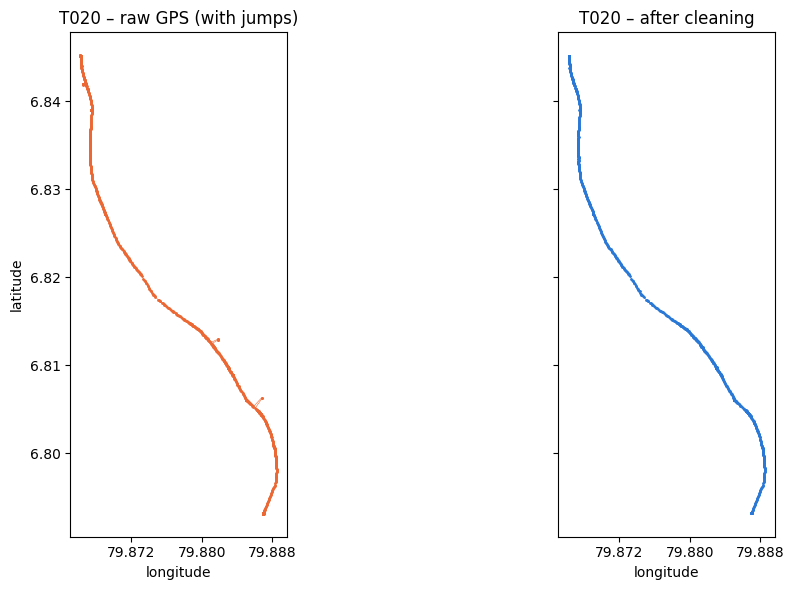

In [11]:
example = cleaning_log[cleaning_log["step"] == "5 GPS jumps"].sort_values("n_affected", ascending=False).iloc[0]["trip_id"]
row = files[files["trip_id"] == example].iloc[0]
raw = load_carscanner(row["path"])
clean = pd.read_csv(OUT_DIR / f"{example}.csv")

raw_fix = raw[["Latitude", "Longtitude"]].dropna().drop_duplicates()
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
axes[0].plot(raw_fix["Longtitude"], raw_fix["Latitude"], ".-", ms=2, lw=0.4, color="#eb6834")
axes[0].set_title(f"{example} – raw GPS (with jumps)")
axes[1].plot(clean["gps_lon"].dropna(), clean["gps_lat"].dropna(), ".-", ms=2, lw=0.4, color="#2a78d6")
axes[1].set_title(f"{example} – after cleaning")
for ax in axes:
    ax.set_aspect("equal"); ax.set_xlabel("longitude")
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
axes[0].set_ylabel("latitude")
plt.tight_layout()
plt.savefig(REPORT_DIR / "before_after_gps.png", dpi=150)
plt.show()

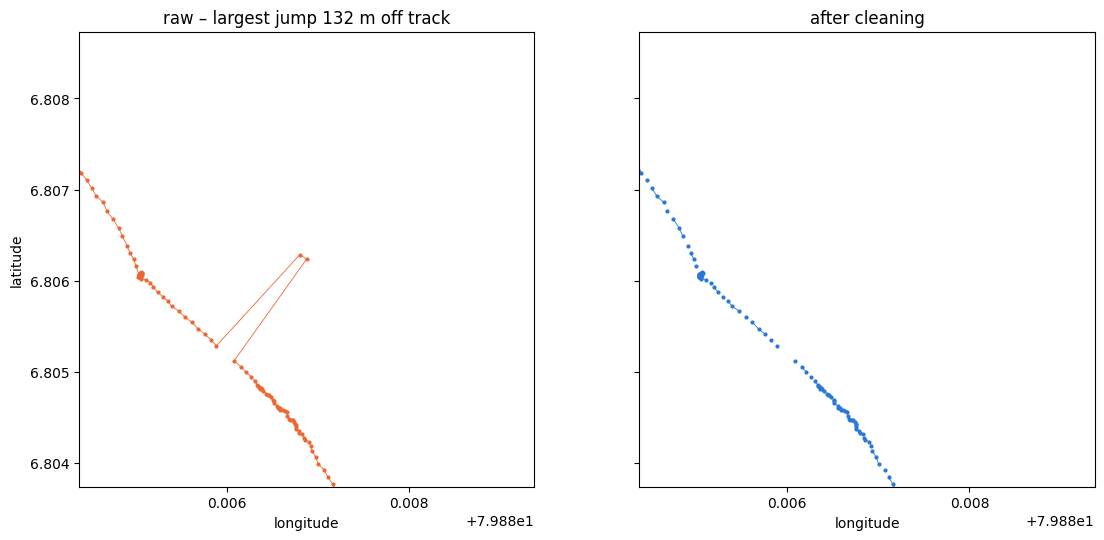

In [12]:
def find_jump_window(raw, clean):
    """Centre of the largest GPS jump, to zoom in on it."""
    fx = raw[["t_s", "Latitude", "Longtitude"]].dropna().drop_duplicates(["Latitude", "Longtitude"])
    med_lat = fx["Latitude"].rolling(11, center=True, min_periods=5).median()
    med_lon = fx["Longtitude"].rolling(11, center=True, min_periods=5).median()
    dev = haversine_m(med_lat, med_lon, fx["Latitude"], fx["Longtitude"])
    i = dev.idxmax()
    return fx.loc[i, "Latitude"], fx.loc[i, "Longtitude"], dev.max()

lat_c, lon_c, d = find_jump_window(raw, clean)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
pad = 0.0025
for ax, (lon, lat, title, col) in zip(axes, [
        (raw_fix["Longtitude"], raw_fix["Latitude"], f"raw – largest jump {d:.0f} m off track", "#eb6834"),
        (clean["gps_lon"], clean["gps_lat"], "after cleaning", "#2a78d6")]):
    ax.plot(lon, lat, ".-", ms=4, lw=0.6, color=col)
    ax.set(xlim=(lon_c - pad, lon_c + pad), ylim=(lat_c - pad, lat_c + pad), title=title, xlabel="longitude")
    ax.set_aspect("equal"); ax.xaxis.set_major_locator(plt.MaxNLocator(3))
axes[0].set_ylabel("latitude")
plt.tight_layout()
plt.savefig(REPORT_DIR / "before_after_gps_zoom.png", dpi=150)
plt.show()

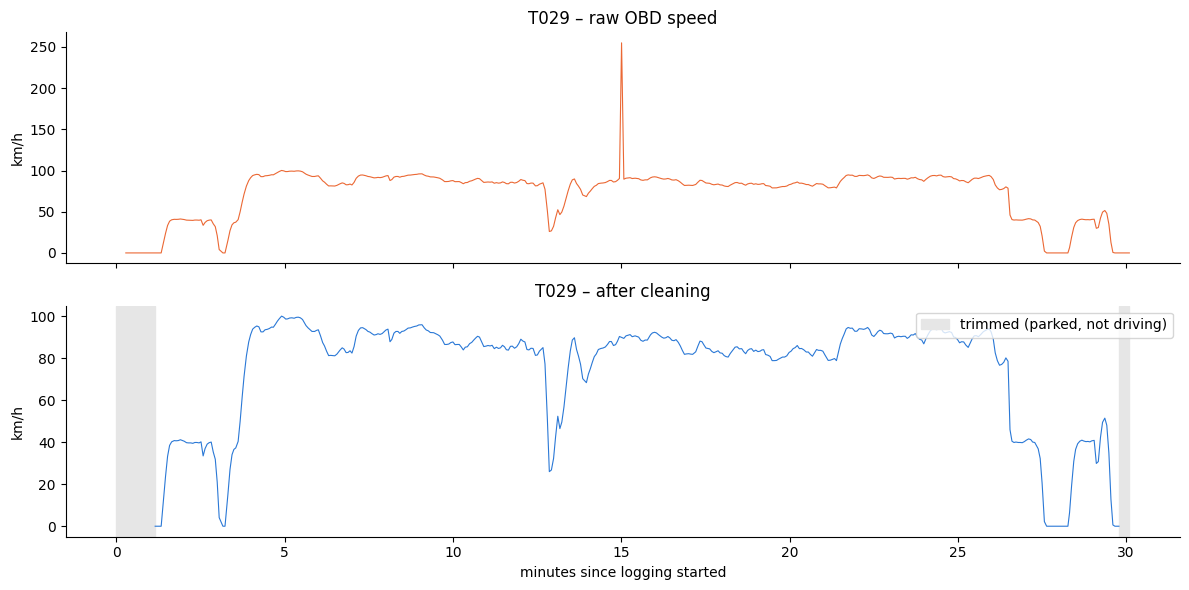

In [13]:
bad_speed = cleaning_log[(cleaning_log["step"] == "3 invalid values") & (cleaning_log["column"] == "speed_kmh")]
example = bad_speed.sort_values("n_affected", ascending=False)["trip_id"].iloc[0]      # a trip with an invalid speed
row = files[files["trip_id"] == example].iloc[0]
raw = load_carscanner(row["path"])
clean = pd.read_csv(OUT_DIR / f"{example}.csv")
m = trip_meta.set_index("trip_id").loc[example]
offset = (pd.to_datetime(m["clean_start"]) - raw["timestamp"].iloc[0]).total_seconds()

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
r = raw[raw["[PDC] Vehicle speed (km/h)"].notna()]
axes[0].plot(r["t_s"] / 60, r["[PDC] Vehicle speed (km/h)"], lw=0.8, color="#eb6834")
axes[0].set(title=f"{example} – raw OBD speed", ylabel="km/h")
c = clean[clean["speed_kmh"].notna()]
axes[1].plot((c["t_s"] + offset) / 60, c["speed_kmh"], lw=0.8, color="#2a78d6")
axes[1].axvspan(0, offset / 60, color="0.9", label="trimmed (parked, not driving)")
axes[1].axvspan((c["t_s"].max() + offset) / 60, r["t_s"].max() / 60, color="0.9")
axes[1].set(title=f"{example} – after cleaning", ylabel="km/h", xlabel="minutes since logging started")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORT_DIR / "before_after_speed.png", dpi=150)
plt.show()

In [14]:
print("STAGE 2 – DATA CLEANING: KEY RESULTS")
print("-" * 60)
print(f"Trips cleaned: {len(trip_meta)}")
print(f"Columns: {len(COLUMN_PLAN)} raw -> {sum(1 for r, n in COLUMN_PLAN.values() if n)} kept "
      f"(every drop documented in column_decisions.csv)")
print(f"Rows: {trip_meta['raw_rows'].sum():,} raw -> {trip_meta['clean_rows'].sum():,} clean")
for _, s in step_summary.iterrows():
    if s["step"].startswith(("1", "3", "4", "5", "6")) and s["total_affected"] > 0:
        print(f"  {s['step']:26s} {s['column']:18s}: {s['total_affected']:6,} values in {s['trips_affected']} trips")
print(f"Idle time trimmed: {summary.loc['raw hours', 'value'] - summary.loc['clean hours', 'value']:.1f} h")
for k, v in gap_table.groupby("type").size().items():
    print(f"Gaps recorded for Stage 3 – {k}: {v}")
print("Verification:", "all checks PASS" if (verification["result"] == "PASS").all() else "see table above")

STAGE 2 – DATA CLEANING: KEY RESULTS
------------------------------------------------------------
Trips cleaned: 77
Columns: 52 raw -> 9 kept (every drop documented in column_decisions.csv)
Rows: 642,588 raw -> 322,910 clean
  1 duplicate rows           all               :     34 values in 12 trips
  3 invalid values           battery_current_a :      4 values in 4 trips
  3 invalid values           battery_voltage_v :      4 values in 4 trips
  3 invalid values           speed_kmh         :      4 values in 4 trips
  4 GPS repeated position    gps_lat/gps_lon   : 479,212 values in 77 trips
  5 GPS jumps                gps_lat/gps_lon   :     86 values in 13 trips
Idle time trimmed: 2.0 h
Gaps recorded for Stage 3 – GPS gap while moving: 13
Gaps recorded for Stage 3 – OBD dropout: 13
Gaps recorded for Stage 3 – logging gap: 3
Verification: all checks PASS


A. Physical basis of each limit


,setting,CFG value,physical value,basis
0,voltage_range_v (low),315.0,315.0,126 cells x 2.5 V
1,voltage_range_v (high),460.0,459.9,126 cells x 3.65 V
2,current_abs_max_a,500.0,476.2,150 kW / 315 V
3,rpm_max,13000.0,12480.0,160 km/h x 78 rpm per km/h
4,spike_accel_ms2,5.0,3.8,0-100 km/h in 7.3 s
5,obd_gap_s,12.0,11.1,3 polling cycles x 3.7 s


B. Clean data vs limits (a large margin means the limit only removes impossible values)


,signal,limit_low,observed_min,p0.1,p99.9,observed_max,limit_high,margin_to_high_%,removed
0,speed_kmh,0,0.0,0.0,99.3,101.0,200,49.5,4
1,motor_rpm,-13000,-5.0,-5.0,7751.1,7863.0,13000,39.5,0
2,battery_voltage_v,315,400.0,403.0,427.0,431.0,460,6.3,4
3,battery_current_a,-500,-130.4,-117.0,125.2,166.3,500,66.7,4
4,soc_pct,0,25.2,25.3,97.6,97.8,100,2.2,0


C. Distance of GPS fixes from their local median track (m):


,count,mean,std,min,50%,90%,99%,99.9%,max
dev_m,162214.0,0.41,2.33,0.0,0.0,1.33,3.25,9.71,161.06


Sensitivity of gps_jump_m (expected from manifest: 14 trips). A flat region around 25 m means the choice is not critical:


,threshold_m,fixes_flagged,trips_flagged,current
0,10,157,23,False
1,15,115,13,False
2,20,100,13,False
3,25,86,13,True
4,35,74,12,False
5,50,62,12,False
6,75,51,11,False


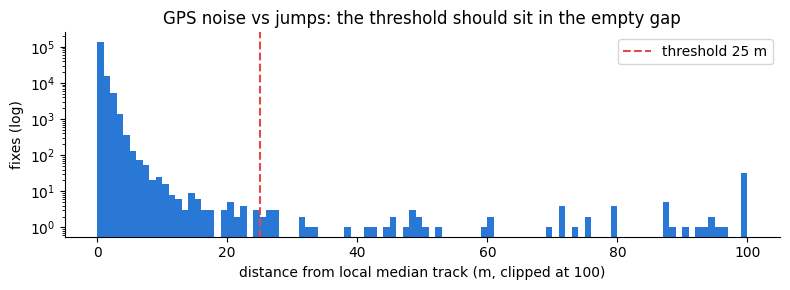

D. Manifest not found - comparing with the counts in SYNTHETIC_DATA_NOTES only


,fault,injected (notes),detected trips
0,duplicate_rows,12,12
1,invalid_values,9,8
2,gps_jumps,14,13
3,gps_freeze,13,13
4,obd_dropout,13,13
5,app_suspended,4,3
6,late_start,7,7
7,early_end,2,2


Note: speed spikes were not injected, so step 6 (spike_accel_ms2) is untested on this data.


In [15]:
# ---------------------------------------------------------------
# Stage 2 threshold validation
#   A. physical arithmetic   B. margin of clean data to each limit
#   C. GPS jump threshold: noise distribution + sensitivity
#   D. detection of injected faults (synthetic manifest)
# ---------------------------------------------------------------
BASE = Path("/content/drive/MyDrive/Colab Notebooks/Component01")

# ---- A. physical arithmetic behind the limits
phys = pd.DataFrame([
    ("voltage_range_v (low)",  CFG["voltage_range_v"][0], 126 * 2.5,       "126 cells x 2.5 V"),
    ("voltage_range_v (high)", CFG["voltage_range_v"][1], 126 * 3.65,      "126 cells x 3.65 V"),
    ("current_abs_max_a",      CFG["current_abs_max_a"],  150_000 / 315,   "150 kW / 315 V"),
    ("rpm_max",                CFG["rpm_max"],            160 * 78,        "160 km/h x 78 rpm per km/h"),
    ("spike_accel_ms2",        CFG["spike_accel_ms2"],    100 / 3.6 / 7.3, "0-100 km/h in 7.3 s"),
    ("obd_gap_s",              CFG["obd_gap_s"],          3 * 3.7,         "3 polling cycles x 3.7 s"),
], columns=["setting", "CFG value", "physical value", "basis"]).round(1)
print("A. Physical basis of each limit"); display(phys)

# ---- B. how close does the CLEAN data come to each limit?
clean = pd.concat([pd.read_csv(OUT_DIR / f"{t}.csv") for t in trip_meta["trip_id"]], ignore_index=True)
lims = {"speed_kmh": (0, CFG["speed_max_kmh"]),
        "motor_rpm": (-CFG["rpm_max"], CFG["rpm_max"]),
        "battery_voltage_v": CFG["voltage_range_v"],
        "battery_current_a": (-CFG["current_abs_max_a"], CFG["current_abs_max_a"]),
        "soc_pct": CFG["soc_range_pct"]}
rows = []
for col, (lo, hi) in lims.items():
    v = clean[col].dropna()
    rows.append({"signal": col, "limit_low": lo, "observed_min": v.min(), "p0.1": v.quantile(0.001),
                 "p99.9": v.quantile(0.999), "observed_max": v.max(), "limit_high": hi,
                 "margin_to_high_%": round(100 * (hi - v.max()) / hi, 1),
                 "removed": int(cleaning_log.query("column == @col and step == '3 invalid values'")["n_affected"].sum())})
margins = pd.DataFrame(rows).round(1)
margins.to_csv(REPORT_DIR / "validation_limit_margins.csv", index=False)
print("B. Clean data vs limits (a large margin means the limit only removes impossible values)")
display(margins)

# ---- C. GPS jump threshold: distance of every genuine fix from its local median track
devs = []
for _, row in files.iterrows():
    raw = load_carscanner(row["path"])
    g = raw[["t_s", "Latitude", "Longtitude"]].apply(pd.to_numeric, errors="coerce").dropna()
    g = g[(g[["Latitude", "Longtitude"]].diff().fillna(1) != 0).any(axis=1)]          # new fixes only (step 4)
    w, h = CFG["gps_jump_window"], CFG["gps_jump_window"] // 2
    mlat = g["Latitude"].rolling(w, center=True, min_periods=5).median()
    mlon = g["Longtitude"].rolling(w, center=True, min_periods=5).median()
    d = haversine_m(mlat, mlon, g["Latitude"], g["Longtitude"])
    ok = (g["t_s"].shift(-h) - g["t_s"].shift(h)) <= CFG["gps_jump_max_window_s"]
    devs.append(pd.DataFrame({"trip_id": row["trip_id"], "dev_m": d[ok].values}))
devs = pd.concat(devs).dropna()

print("C. Distance of GPS fixes from their local median track (m):")
display(devs["dev_m"].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(2).to_frame().T)
sens = pd.DataFrame([{"threshold_m": thr, "fixes_flagged": int((devs["dev_m"] > thr).sum()),
                      "trips_flagged": devs.loc[devs["dev_m"] > thr, "trip_id"].nunique()}
                     for thr in (10, 15, 20, 25, 35, 50, 75)])
sens["current"] = sens["threshold_m"] == CFG["gps_jump_m"]
sens.to_csv(REPORT_DIR / "validation_gps_jump_sensitivity.csv", index=False)
print(f"Sensitivity of gps_jump_m (expected from manifest: 14 trips). "
      f"A flat region around {CFG['gps_jump_m']} m means the choice is not critical:")
display(sens)

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(devs["dev_m"].clip(upper=100), bins=np.arange(0, 101, 1), color="#2a78d6")
ax.axvline(CFG["gps_jump_m"], color="#e34948", ls="--", label=f"threshold {CFG['gps_jump_m']} m")
ax.set(yscale="log", xlabel="distance from local median track (m, clipped at 100)", ylabel="fixes (log)",
       title="GPS noise vs jumps: the threshold should sit in the empty gap")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(REPORT_DIR / "validation_gps_jump_hist.png", dpi=150); plt.show()

# ---- D. injected faults: expected (manifest) vs detected (Stage 2)
trips_with = lambda step: set(cleaning_log.query("step == @step and n_affected > 0")["trip_id"])
gap_trips = lambda typ: set(gap_table.loc[gap_table["type"] == typ, "trip_id"])
detected = {
    "duplicate_rows": trips_with("1 duplicate rows"),
    "invalid_values": trips_with("3 invalid values"),
    "gps_jumps":      trips_with("5 GPS jumps"),
    "gps_freeze":     gap_trips("GPS gap while moving"),
    "obd_dropout":    gap_trips("OBD dropout"),
    "app_suspended":  gap_trips("logging gap"),
    "late_start":     set(trip_meta.loc[trip_meta["starts_while_moving"], "trip_id"]),
    "early_end":      set(trip_meta.loc[trip_meta["ends_while_moving"], "trip_id"]),
}
notes_counts = {"duplicate_rows": 12, "invalid_values": 9, "gps_jumps": 14, "gps_freeze": 13,
                "obd_dropout": 13, "app_suspended": 4, "late_start": 7, "early_end": 2}

manifest_path = next(BASE.rglob("synthetic_manifest.csv"), None)
file_to_trip = dict(zip(files["file"], files["trip_id"]))
rows = []
if manifest_path:
    man = pd.read_csv(manifest_path)
    fcol = max(man.columns, key=lambda c: man[c].astype(str).isin(files["file"]).sum())
    text = man.astype(str).agg(" ".join, axis=1)
    for fault, det in detected.items():
        exp = {file_to_trip.get(f) for f in man.loc[text.str.contains(fault), fcol]} - {None}
        rows.append({"fault": fault, "injected": len(exp), "detected": len(det),
                     "caught": len(exp & det), "missed_trips": ", ".join(sorted(exp - det)) or "-",
                     "extra_trips": ", ".join(sorted(det - exp)) or "-"})
    print(f"D. Injected faults vs Stage 2 detection (manifest: {manifest_path.relative_to(BASE)})")
else:
    for fault, det in detected.items():
        rows.append({"fault": fault, "injected (notes)": notes_counts[fault], "detected trips": len(det)})
    print("D. Manifest not found - comparing with the counts in SYNTHETIC_DATA_NOTES only")
recall = pd.DataFrame(rows)
recall.to_csv(REPORT_DIR / "validation_fault_detection.csv", index=False)
display(recall)
print("Note: speed spikes were not injected, so step 6 (spike_accel_ms2) is untested on this data.")